## **다중 LLM 활용 + ReAct 에이전트 (LangChain 버전)**
- 순차 / 병렬 Multi-LLM + GPT 종합 구조, 그리고 ReAct(생각 → 행동 → 관찰) 루프
- basicedu에서는 **OpenAI / Google / Ollama SDK 를 직접** 호출했습니다.
- 이 노트북은 같은 예제를 **LangChain 1.x** 로 다시 작성했습니다. (기능은 그대로, 코드는 훨씬 짧고 모델 교체가 쉬워집니다)

| 사용 버전 (2026-10 기준) | 패키지 |
|---|---|
| `langchain` 1.4.x | `create_agent`, 메시지/도구 표준 인터페이스 |
| `langchain-core` 1.6.x | `Runnable`, LCEL(`\|`), `@tool`, `RunnableParallel` |
| `langchain-openai` 1.7.x | `ChatOpenAI` |
| `langchain-google-genai` 4.4.x | `ChatGoogleGenerativeAI` |
| `langchain-ollama` 1.1.x | `ChatOllama` |
| `langgraph` 1.2.x | `create_agent` 가 내부적으로 사용 (직접 import 할 일은 거의 없음) |

> **한눈에 보기**
> - 10/16 다중 LLM·ReAct를 LangChain 1.x로: `ChatOpenAI`·`ChatGoogleGenerativeAI`·`ChatOllama`를 같은 `invoke()`로
> - 병렬은 `RunnableParallel`, 순차는 `RunnablePassthrough.assign()`으로 `spec → code → review`를 state dict에 쌓기
> - ReAct: `bind_tools` + `ToolMessage`로 루프 직접 → `create_agent` + `stream_mode="updates"`로 Thought/Action/Observation
> - 실행 결과의 문제: 작은 로컬 모델의 `<think>`·지시 무시, 도구 결과 없이 계산, 예산 초과 장소 추천
> - 정리 문서: [다중LLM과ReAct_LangChain.md](다중LLM과ReAct_LangChain.md) · 강의 슬라이드 이미지 포함, 📝 정리 셀은 직접 정리

### 전체 흐름 한눈에 보기

### 원본(직접 SDK) → LangChain 으로 달라지는 점

| 구분 | 원본 (exam4) | LangChain 버전 (exam11) |
|---|---|---|
| 모델 객체 | `OpenAI()` / `genai.Client()` / `OpenAI(base_url=ollama)` — **3가지 다른 SDK** | `ChatOpenAI` / `ChatGoogleGenerativeAI` / `ChatOllama` — **모두 같은 인터페이스** (`invoke`) |
| 호출 방식 | `responses.create(...)`, `models.generate_content(...)`, `chat.completions.create(...)` | `chain.invoke(...)` 하나로 통일 |
| 프롬프트 | 파이썬 f-string 을 직접 조립 | `ChatPromptTemplate` (역할/변수 분리, 재사용) |
| 응답 꺼내기 | `response.output_text` / `response.text` / `choices[0].message.content` | `StrOutputParser()` (또는 `message.text`) |
| 병렬 실행 | `ThreadPoolExecutor` + `submit()` + `Future.result()` | `RunnableParallel` / `RunnablePassthrough.assign` (내부에서 자동 병렬) |
| 순차 실행 | 함수 3개를 `main()` 에서 차례로 호출 | `\|` 로 이어 붙인 **하나의 체인** (LCEL) |
| 도구 정의 | JSON 스키마를 손으로 작성 (`TOOLS = [{...}]`) | `@tool` — 함수 + 타입힌트 + docstring 에서 **스키마 자동 생성** |
| 도구 실행 | `call_tool()` 분기문(if/elif) | 도구 객체의 `.invoke()` (이름으로 찾아 호출) |
| 대화 기록 | `input_items` (dict + `response.output`) | `HumanMessage` / `AIMessage` / `ToolMessage` **클래스** |
| ReAct 루프 | `while` / `for` 루프를 직접 작성 | `create_agent(...)` 한 번 (내부는 LangGraph 의 model ⇄ tools 루프) |

> 💡 **핵심**: 모델이 무엇이든(OpenAI, Google, 로컬 Ollama) 코드의 나머지는 바뀌지 않습니다.

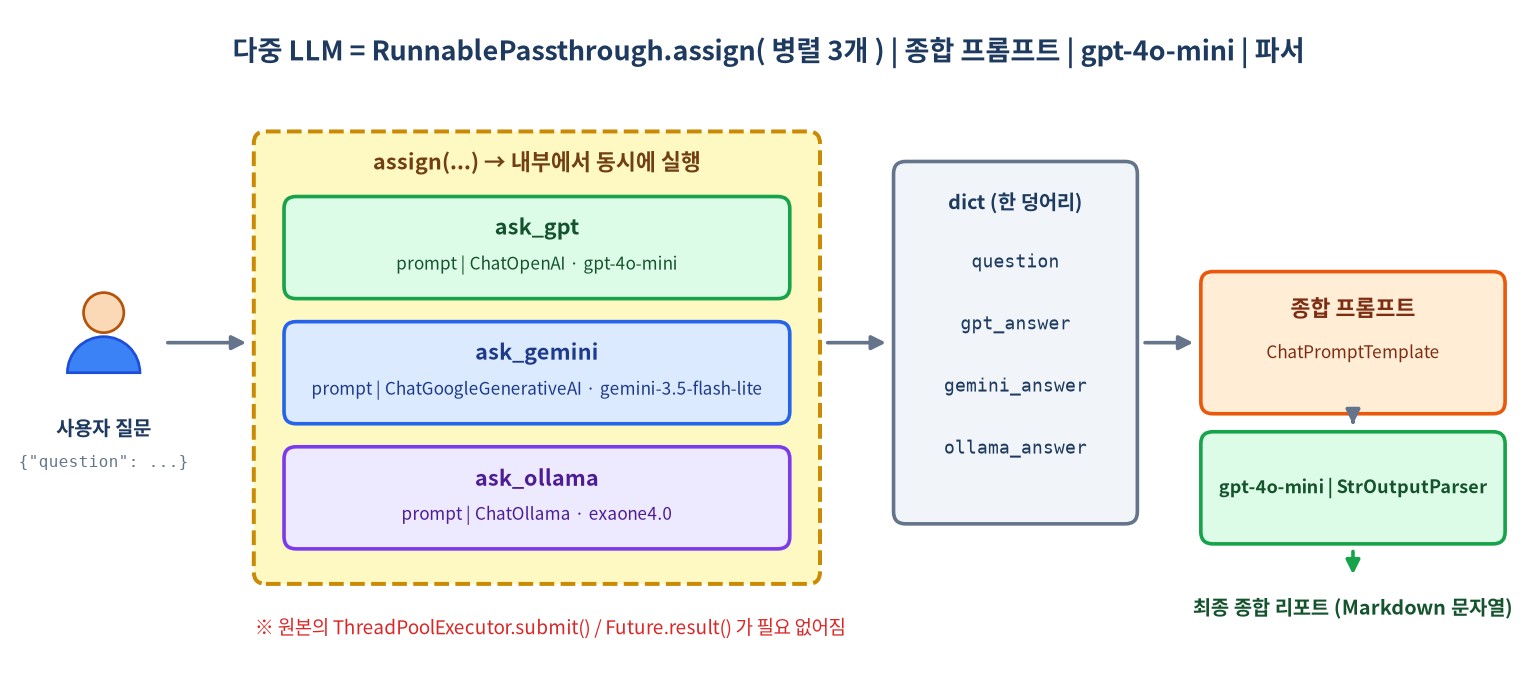

### 준비 사항

**1) 패키지 설치** 
```
pip install -U langchain-google-genai
```

**2) API 키** — 프로젝트 폴더의 `.env` 파일(또는 환경 변수)에 넣어 둡니다.
```
OPENAI_API_KEY=sk-...
GOOGLE_API_KEY=...        # GEMINI_API_KEY 라는 이름도 인식됩니다
```

**3) Ollama (로컬 모델)** — 터미널에서 한 번만 내려받으면 됩니다.
```
ollama pull ingu627/exaone4.0:1.2b
ollama cp ingu627/exaone4.0:1.2b   exanone4.0
```

> ⚠️ **Gemini 3.5 Flash-Lite 주의점**: 마지막 메시지가 모델(AI) 메시지인 요청은 지원되지 않습니다. 항상 **사용자(Human) 메시지로 끝나게** 보내세요. `temperature` 도 기본값을 유지하는 것이 권장됩니다. (이 노트북의 코드는 모두 이 규칙을 지킵니다.)

In [10]:
%pip install -U langchain-google-genai

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import os
import time
from langchain_openai import ChatOpenAI
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_ollama import ChatOllama

# ------------------------------------------------------------
# 3개의 모델 객체 — 클래스만 다를 뿐, 사용법(invoke)은 모두 똑같습니다.
# ------------------------------------------------------------
# 1. OpenAI (gpt-4o-mini)           ← OPENAI_API_KEY 환경 변수를 자동으로 사용
gpt = ChatOpenAI(model="gpt-4o-mini")

# 2. Google (gemini-3.5-flash-lite) ← GOOGLE_API_KEY(또는 GEMINI_API_KEY) 자동 사용
gemini = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

# 3. 로컬 Ollama (EXAONE 4.0)       ← 원본처럼 OpenAI 호환 주소를 흉내 낼 필요 없이 전용 클래스 사용
OLLAMA_MODEL = "exaone4.0"          # 사용 중인 모델명으로 변경 (예: "exaone4.0:1.2b")
ollama = ChatOllama(model=OLLAMA_MODEL, base_url="http://localhost:11434")

# 모델이 잘 붙었는지 가볍게 확인 (3개 모두 같은 방식으로 호출)
for name, llm in [("gpt", gpt), ("gemini", gemini), ("ollama", ollama)]:
    try:
        print(name, "→", llm.invoke("한글 한 단어로 인사해줘").text)
    except Exception as e:
        print(name, "→ 연결 실패:", e)

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


gpt → 안녕하세요!
gemini → 안녕.
ollama → Okay, user just asked for a Korean hello-hi phrase in one word. Simple request!  

Hmm, they didn't specify formal/informal tone though. Since they're asking for minimal phrasing, probably prefer casual or universal terms. "안녕하세요" is polite but slightly verbose for this context... maybe shorter options?  

Ah! "안녕" alone works perfectly as an abbreviation - keeps it ultra-concise while sounding natural. User seems quick and efficient here. No need for explanations unless they ask follow-ups.  

Should I add alternatives? Nah, they said "one word" specifically. Overloading with options might annoy them. Stick to clean answer.
</think>

안녕하세요! 😊


**📝 정리** — 세 모델 모두 같은 `invoke()`로 응답했다(10/16에 에러였던 Gemini도 정상). EXAONE 4.0 1.2B는 **영어 `<think>` 추론을 답에 그대로 섞어** 냈고, "한 단어"라는 지시도 지키지 않았다. 추론 모델의 출력은 `<think>...</think>`를 잘라 내고 써야 한다.

#### 체인(Chain) 만들기 — `prompt | llm | parser`

LangChain 에서는 **프롬프트 → 모델 → 출력 파서**를 `|` 로 이어 붙이면 그것이 곧 하나의 실행 가능한 객체(**Runnable**)가 됩니다.

```
ChatPromptTemplate  |  ChatOpenAI  |  StrOutputParser
 (질문을 메시지로)     (모델 호출)      (AIMessage → 문자열)
```

- 모든 Runnable 은 `invoke`(1건), `batch`(여러 건), `stream`(조금씩), `ainvoke`(비동기)를 **공통으로** 가집니다.
- `StrOutputParser` 덕분에 원본의 `response.output_text` / `response.text` / `choices[0].message.content` 가 사라집니다.
- 원본의 `try / except` (실패하면 에러 문자열을 돌려주기)는 `safe()` 로 감싸서 그대로 유지했습니다.
  (대안: `chain.with_fallbacks([...])` — 실패 시 다른 체인으로 자동 대체)

In [12]:
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnableLambda, RunnablePassthrough, RunnableParallel

parser = StrOutputParser()

def build_chain(llm, system: str | None = None):
    """프롬프트 | 모델 | 파서 로 이루어진 '질문 → 답변 문자열' 체인을 만든다."""
    messages = []
    if system:                                   # 원본: instructions=... (역할 부여)
        messages.append(("system", system))
    messages.append(("human", "{question}"))     # {question} 자리에 입력값이 들어간다
    return ChatPromptTemplate.from_messages(messages) | llm | parser

def safe(chain, name: str):
    """원본의 try/except 와 같은 역할: 한 모델이 실패해도 전체 흐름이 멈추지 않게 한다."""
    def _run(inputs, config):                    # config 를 넘겨야 추적(LangSmith) 정보가 이어진다
        try:
            return chain.invoke(inputs, config)
        except Exception as e:
            return f"{name} 에러 (키/모델/서버 확인 필요): {e}"
    return RunnableLambda(_run)


# 원본의 ask_gpt / ask_gemini / ask_ollama 에 해당 — 이제 '함수'가 아니라 '체인'입니다.
ask_gpt    = safe(build_chain(gpt, "당신은 분석적이고 객관적인 IT 전문가입니다."), "OpenAI")
ask_gemini = safe(build_chain(gemini), "Gemini")
ask_ollama = safe(build_chain(ollama), "Ollama")

print(ask_gpt.invoke({"question": "FastAPI 를 한 문장으로 소개해줘"}))

FastAPI는 Python으로 작성된 현대적인 웹 프레임워크로, 고속의 API를 쉽게 구축할 수 있도록 비동기 지원과 자동 문서화를 제공하는 도구입니다.


#### 1단계: 3개 모델에게 동시에 묻기 → 2단계: GPT 가 종합

먼저 **단계별로** 실행해서 중간 결과를 눈으로 확인합니다.

- `RunnableParallel(gpt=..., gemini=..., ollama=...)` : 같은 입력을 3개 체인에 **동시에** 보내고, 결과를 `{"gpt": ..., "gemini": ..., "ollama": ...}` 딕셔너리로 돌려줍니다.
- 종합 프롬프트는 `ChatPromptTemplate` 의 `{변수}` 에 3개 답변을 끼워 넣습니다. (원본의 f-string 과 같은 역할)

In [13]:
from IPython.display import Markdown, display

user_question = "초보 개발자의 첫 웹 백엔드 스택으로 Python FastAPI와 Java Spring Boot 중 무엇을 더 추천하나요?"

print(f"❓ 공동 질문: '{user_question}'\n")
print("==============================================")
print("🔄 1단계: 3개의 다중 LLM에게 동시에 의견 묻는 중...")
print("==============================================\n")

# 원본의 ThreadPoolExecutor(max_workers=3) + submit() + result() 세 번 ... 을 이 한 줄이 대신합니다.
parallel = RunnableParallel(gpt=ask_gpt, gemini=ask_gemini, ollama=ask_ollama)

start = time.perf_counter()
answers = parallel.invoke({"question": user_question})        # 3개가 동시에 실행되고, 모두 끝나면 dict 반환
print(f"⏱️ 3개 모델 답변 수집 완료: {time.perf_counter() - start:.1f}초 (가장 느린 모델 기준)\n")

print("🤖 [OpenAI gpt-4o-mini]\n", answers["gpt"][:200], "...\n")
print("♊ [Google gemini-3.5-flash-lite]\n", answers["gemini"][:200], "...\n")
print("🦙 [Ollama 로컬 모델]\n", answers["ollama"][:200], "...\n")

❓ 공동 질문: '초보 개발자의 첫 웹 백엔드 스택으로 Python FastAPI와 Java Spring Boot 중 무엇을 더 추천하나요?'

🔄 1단계: 3개의 다중 LLM에게 동시에 의견 묻는 중...

⏱️ 3개 모델 답변 수집 완료: 34.9초 (가장 느린 모델 기준)

🤖 [OpenAI gpt-4o-mini]
 Python FastAPI와 Java Spring Boot는 각각의 장점과 특징을 가지고 있으며, 초보 개발자의 첫 웹 백엔드 스택으로 어떤 것을 선택할지 결정하는 데는 몇 가지 고려해야 할 요소가 있습니다.

### Python FastAPI

**장점:**
1. **간단한 문법**: Python의 문법은 직관적이고 간결하여 초보자가 배우기 용이합니다.
 ...

♊ [Google gemini-3.5-flash-lite]
 초보 개발자의 첫 웹 백엔드 스택으로는 **Java Spring Boot**를 더 추천합니다. 

많은 사람들이 "FastAPI가 배우기 쉽고 파이썬이 친숙하다"는 이유로 FastAPI를 추천하지만, **취업, 개발자로서의 성장, 그리고 웹 백엔드의 본질을 이해하는 측면**에서는 Spring Boot가 훨씬 더 탄탄한 기반을 만들어 줍니다.

두 기술을 비 ...

🦙 [Ollama 로컬 모델]
 우선 사용자의 질문을 분석해보겠습니다. 초보 개발자를 대상으로 Python FastAPI와 Java Spring Boot 중 어떤 것을 더 추천할지 묻고 있습니다. 
사용자의 배경은 '초보 개발자'라는 점을 고려해야 합니다. 따라서 두 기술 모두 장점이 있지만, 초보자에게 진입 장벽이 낮은 쪽을 선택하는 것이 중요합니다.

FastAPI 관련 장점:
- P ...



**📝 정리** — `RunnableParallel`로 동시에 물어 34.9초(가장 느린 모델 기준). Gemini는 Spring Boot를 분명히 추천, GPT는 장단점 나열, EXAONE은 생각 과정을 길게 적었다.

In [14]:

# ------------------------------------------------------------
# 종합 프롬프트 (원본의 synthesis_prompt 와 동일한 내용)
# ------------------------------------------------------------
synthesis_prompt = ChatPromptTemplate.from_messages([
    ("system", "당신은 수석 아키텍트이자 마스터 멘토입니다."),
    ("human", """아래는 동일한 질문에 대해 3개의 서로 다른 AI 모델(GPT, Gemini, 오픈소스 모델)이 내놓은 답변입니다.

[질문]
{question}

---
[AI 1: GPT의 의견]
{gpt_answer}

---
[AI 2: Gemini의 의견]
{gemini_answer}

---
[AI 3: 오픈소스 모델의 의견]
{ollama_answer}
---

위 3가지 시각을 종합 분석하여, 공통적인 핵심 권장 사항을 추려내고,
각 AI의 답변 스타일 차이점을 가볍게 평가하는 '최종 종합 가이드 리포트'를 깔끔한 마크다운 양식으로 작성해 주세요."""),
])

print("==============================================")
print("🔄 2단계: 수집된 의견들을 종합 요약하는 중 (by gpt-4o-mini)...")
print("==============================================\n")

synthesis_chain = synthesis_prompt | gpt | parser
final_report = synthesis_chain.invoke({
    "question": user_question,
    "gpt_answer": answers["gpt"],
    "gemini_answer": answers["gemini"],
    "ollama_answer": answers["ollama"],
})

print("✨ [최종 다중 LLM 취합 리포트] ✨\n")
display(Markdown(final_report))        # 마크다운 그대로 예쁘게 출력

🔄 2단계: 수집된 의견들을 종합 요약하는 중 (by gpt-4o-mini)...

✨ [최종 다중 LLM 취합 리포트] ✨



# 최종 종합 가이드 리포트: 초보 개발자를 위한 Python FastAPI vs Java Spring Boot

## 질문 요약
초보 개발자가 첫 웹 백엔드 스택으로 Python FastAPI와 Java Spring Boot 중 무엇을 선택해야 하는지를 분석합니다.

## 공통적인 핵심 권장 사항

1. **Python FastAPI**
   - **추천 대상**: Python에 익숙하거나 프로토타입 및 개인 프로젝트를 빠르게 개발하고 싶은 초보자.
   - **장점**:
     - 간단하고 직관적인 문법.
     - 신속한 개발이 가능하여 프로토타입 제작에 유리.
     - 비동기 처리 및 자동 문서화 기능이 제공됨.
   - **단점**:
     - 대규모 애플리케이션에서의 생태계 성숙도가 낮을 수 있음.
     - 성능 면에서 Java에 비해 상대적으로 느릴 수 있음.
   - **결론**: Python에 익숙한 경우 FastAPI를 통해 빠르게 배울 수 있으며, 데이터 사이언스와 AI 연동이 필요할 때 적합.

2. **Java Spring Boot**
   - **추천 대상**: 대규모 시스템 구축 경험과 엔터프라이즈 개발 환경을 염두에 두고 있는 초보자.
   - **장점**:
     - 안정적인 생태계와 방대한 커뮤니티 지원.
     - 대규모 애플리케이션에서 검증된 제품으로의 배포 용이.
     - 객체지향 설계 및 구조를 심도 있게 학습할 수 있음.
   - **단점**:
     - 초기 설정이 복잡하고 학습 곡선이 가파를 수 있음.
     - 메모리 사용량이 상대적으로 높아 효율성 문제 발생 가능.
   - **결론**: Java 생태계에 진입하고자 하는 경우, Spring Boot는 탄탄한 기반을 제공하여 취업 기회를 높이는 데 유리.

## AI 답변 스타일 차이

- **AI 1 (GPT)**:
  - **스타일**: 균형 잡힌 분석과 장단점 제시. 
  - **차별화 점**: 각 프레임워크의 사용 시나리오를 명확히 정리하고, 초보자에게 친숙한 언어 및 기술 스택 추천.
  
- **AI 2 (Gemini)**:
  - **스타일**: 보다 힘 있는 주장을 통해 Spring Boot의 중요성을 강조.
  - **차별화 점**: 취업 및 성장 관점에서 선택의 기준을 명확히 하며, 경험을 통한 구체적인 상황 제시로 설득력 강화.

- **AI 3 (오픈소스 모델)**:
  - **스타일**: 분석적이고 기술적인 접근.
  - **차별화 점**: 명확한 기술적 세부사항 및 코드 예제를 통해 실용적인 이해를 돕고, 특정 조건에서 두 프레임워크의 적합성을 논의.

## 결론
각 기술 스택은 고유의 장점과 단점을 가지고 있으며, 초보자의 목적과 배경에 따라 선택이 달라질 수 있습니다. 프로토타입과 빠른 개발을 중시한다면 FastAPI를, 장기적인 취업과 대규모 프로젝트에 대한 준비를 원한다면 Spring Boot를 추천합니다. 이 리포트가 초보 개발자가 자신의 목표에 맞는 백엔드 스택을 선택하는 데 도움이 되기를 바랍니다.

### `ThreadPoolExecutor` 는 어디로 갔을까? — `RunnableParallel` 이 대신합니다

원본에서는 "직원 3명에게 일을 동시에 시키는" 코드를 직접 짰습니다. LangChain 은 이 부분을 **내부에서 알아서** 처리합니다.

| 원본 개념 | LangChain 에서는 |
|---|---|
| `ThreadPoolExecutor(max_workers=3)` — 동시에 일할 직원 수 | `RunnableParallel` 이 내부 스레드 풀로 실행. 동시 실행 수 제한은 `config={"max_concurrency": 3}` |
| `executor.submit(ask_gpt, q)` — "일 시작해!" (기다리지 않음) | `RunnableParallel(gpt=ask_gpt, ...)` 처럼 **선언만** 하면 끝 |
| `Future` — 나중에 받을 결과의 "예약증" | 필요 없음. 결과는 `invoke()` 가 끝나면 dict 로 한 번에 도착 |
| `future.result()` — 끝날 때까지 기다렸다가 결과 받기 | `answers["gpt"]` 처럼 dict 에서 꺼내기만 하면 됨 |

```
시간 →
GPT    : [-----요청 처리 중-----] 완료
Gemini : [---요청 처리 중---]      완료
Ollama : [--------요청 처리 중--------] 완료  ← 가장 느린 모델이 끝나는 시점에 invoke() 가 반환
         ↑
         여기서 3개 요청이 동시에 시작됨
```

**비동기(`async`) 버전도 거의 공짜입니다.** 노트북에서는 `await` 를 바로 쓸 수 있습니다.
```python
answers = await parallel.ainvoke({"question": user_question})   # 스레드 대신 asyncio 로 동시 실행
```
**같은 질문 여러 개를 한 모델에 동시에** 보내고 싶다면 `llm.batch([...], config={"max_concurrency": 3})` 를 씁니다.

### 한 번에 이어 붙이기 — "병렬 수집 + 종합"을 하나의 체인으로

`RunnablePassthrough.assign(키=체인, ...)` 은 **입력 딕셔너리는 그대로 두고, 새 키를 추가**합니다. 이때 `assign` 안의 체인들은 **병렬로** 실행됩니다.

```
{"question": ...}
   └─ assign ─▶ {"question", "gpt_answer", "gemini_answer", "ollama_answer"}   ← 3개 동시 실행
                    └─ synthesis_prompt | gpt | parser ─▶ 최종 리포트(문자열)
```
앞 셀의 코드 20여 줄이 아래의 **체인 선언 한 덩어리**로 줄어듭니다.

In [15]:
report_chain = (
    RunnablePassthrough.assign(          # question 은 그대로 두고, 3개 답변을 병렬로 추가
        gpt_answer=ask_gpt,
        gemini_answer=ask_gemini,
        ollama_answer=ask_ollama,
    )
    | synthesis_prompt                   # 위 4개 값({question, *_answer})이 프롬프트의 {변수}에 들어감
    | gpt                                # 최종 종합은 가장 신뢰하는 gpt-4o-mini 가 담당
    | parser
)

report = report_chain.invoke({"question": user_question})
display(Markdown(report))

# 최종 종합 가이드 리포트: Python FastAPI vs Java Spring Boot

## 1. 공통적인 핵심 권장 사항

| 프레임워크           | 추천 사항                                                                                                           |
|---------------------|---------------------------------------------------------------------------------------------------------------------|
| **Python FastAPI**  | - 초보자가 빠르게 웹 서비스를 개발하고 싶다면 FastAPI를 선택하십시오.<br>- Python의 간단한 문법과 자동 문서화 기능 덕분에 프로토타입을 만드는 데 매우 유용합니다.            |
| **Java Spring Boot**| - 취업을 목표로 하거나 엔터프라이즈 수준 애플리케이션 개발에 관심이 있다면 Spring Boot를 추천합니다.<br>- 풍부한 자료와 커뮤니티 지원으로 이후 개발에 많은 도움이 됩니다. |

## 2. 장단점 요약

### Python FastAPI
**장점:**
- 직관적인 문법으로 학습 용이
- 비동기 처리 지원 및 높은 성능
- 자동 문서화 기능
- 빠른 프로토타이핑과 효율적인 데이터 모델링

**단점:**
- 상대적으로 작은 생태계
- 개발자가 아키텍처 설계를 직접 해야 할 수 있어 혼란스러울 수 있음

### Java Spring Boot
**장점:**
- 성숙한 생태계와 안정성
- 다양한 내장 기능과 모듈 제공
- 대규모 시스템에서의 높은 신뢰성

**단점:**
- 높은 진입 장벽 및 복잡한 학습 곡선
- 보일러플레이트 코드가 많아 번거로움

## 3. AI 답변 스타일 평가

- **AI 1 (GPT의 의견)**: 장단점을 명확하게 나열하고, 개인의 필요에 따른 추천을 통해 균형 잡힌 시각을 제시.
- **AI 2 (Gemini의 의견)**: 경험 기반으로 추천 대상을 명확하게 구분하여, 사용자 맞춤형 정보를 제공. 취업 시장과 관련된 현실적인 조언 포함.
- **AI 3 (오픈소스 모델의 의견)**: 기술적 세부사항과 현대적 트렌드에 집중하여 FastAPI의 장점을 강조. Spring Boot의 고려 사항을 상세히 설명.

## 4. 최종 결론

- 빠른 프로토타입 개발 및 웹 경험을 원하는 초보자는 **Python FastAPI**로 시작하는 것이 좋습니다. 
- 한국의 취업 시장에서 경쟁력 있는 경력을 쌓고자 하는 초보자는 **Java Spring Boot**를 선택하는 것이 바람직합니다.
- 두 기술을 비교학습하여, FastAPI로 기초를 다진 후, Spring Boot로 확장하는 접근법도 효과적일 수 있습니다. 

이 종합 가이드는 초보 개발자들이 개인의 상황과 목표에 맞는 선택을 할 수 있도록 도움을 줄 것입니다.

**📝 정리** — `assign`으로 수집 + 종합을 체인 하나로 묶었다. 종합 리포트는 "빠른 개발이면 FastAPI, 취업·대규모면 Spring Boot"로 정리했다.

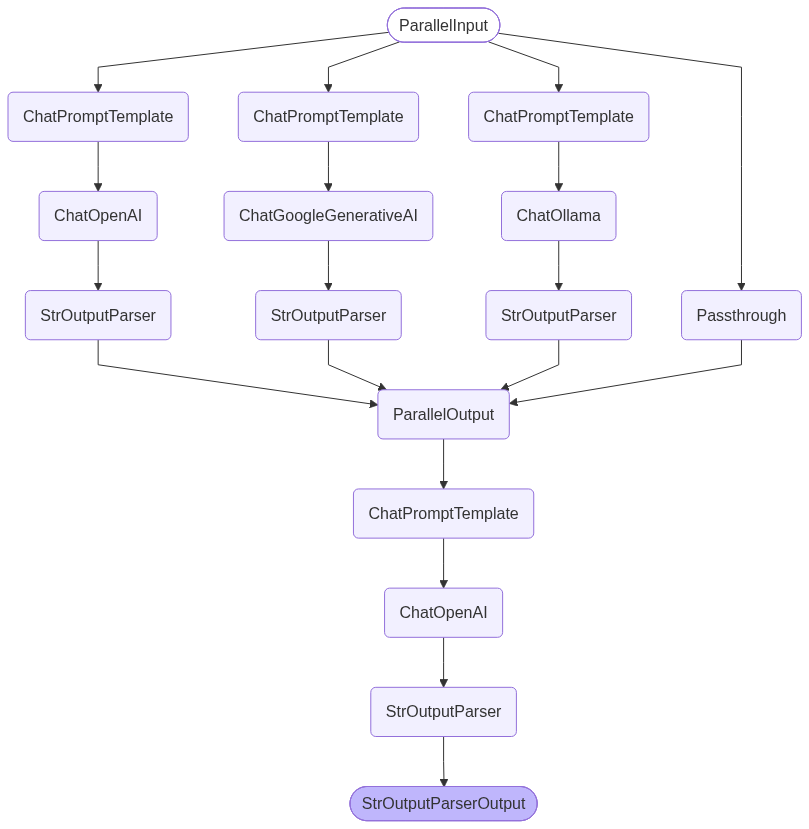

In [16]:
# 체인의 구조를 그림으로 확인 (인터넷이 되면 PNG, 안 되면 Mermaid 코드 출력)
from IPython.display import Image, display

def show_graph(runnable, **kw):
    try:
        g = runnable.get_graph(**kw)
    except TypeError:                       # xray 옵션이 없는 Runnable 용
        g = runnable.get_graph()
    try:
        display(Image(g.draw_mermaid_png()))        # mermaid.ink 로 렌더링 → 인터넷 필요
    except Exception as e:
        print(f"(PNG 렌더링 실패: {type(e).__name__}) → 아래 Mermaid 코드를 https://mermaid.live 에 붙여 넣어 보세요\n")
        print(g.draw_mermaid())


show_graph(report_chain)

**다중 LLM - 순차 파이프라인 패턴**

- gemini-3.5-flash-lite → **시스템 아키텍트** (고수준 설계/명세 작성에 강점)
- Ollama/exaone 4.0 (로컬) → **풀스택 개발자** (실제 코드 생성)
- gpt-4o-mini → **시니어 QA 리뷰어** (엄격한 검증/판정)

**LangChain 으로 바뀌는 부분**

- 에이전트 함수 3개(`run_planner_agent` …)가 **체인 3개**가 됩니다. (`프롬프트 | 모델 | 파서`)
- 함수 사이에서 결과를 손으로 넘기던 코드(`spec_result`, `code_result` 변수) 대신,
  **`RunnablePassthrough.assign()` 이 딕셔너리에 결과를 한 칸씩 쌓아 줍니다.**
- 역할 지시는 `("system", ...)`, 실제 입력은 `("human", ...)` 로 나눕니다. (Gemini 는 system 메시지를 `system_instruction` 으로 자동 변환)
- `inspect.cleandoc(...)` 로 들여쓰기를 정리하던 f-string 은 필요 없습니다. 프롬프트 템플릿이 변수 치환을 맡습니다.

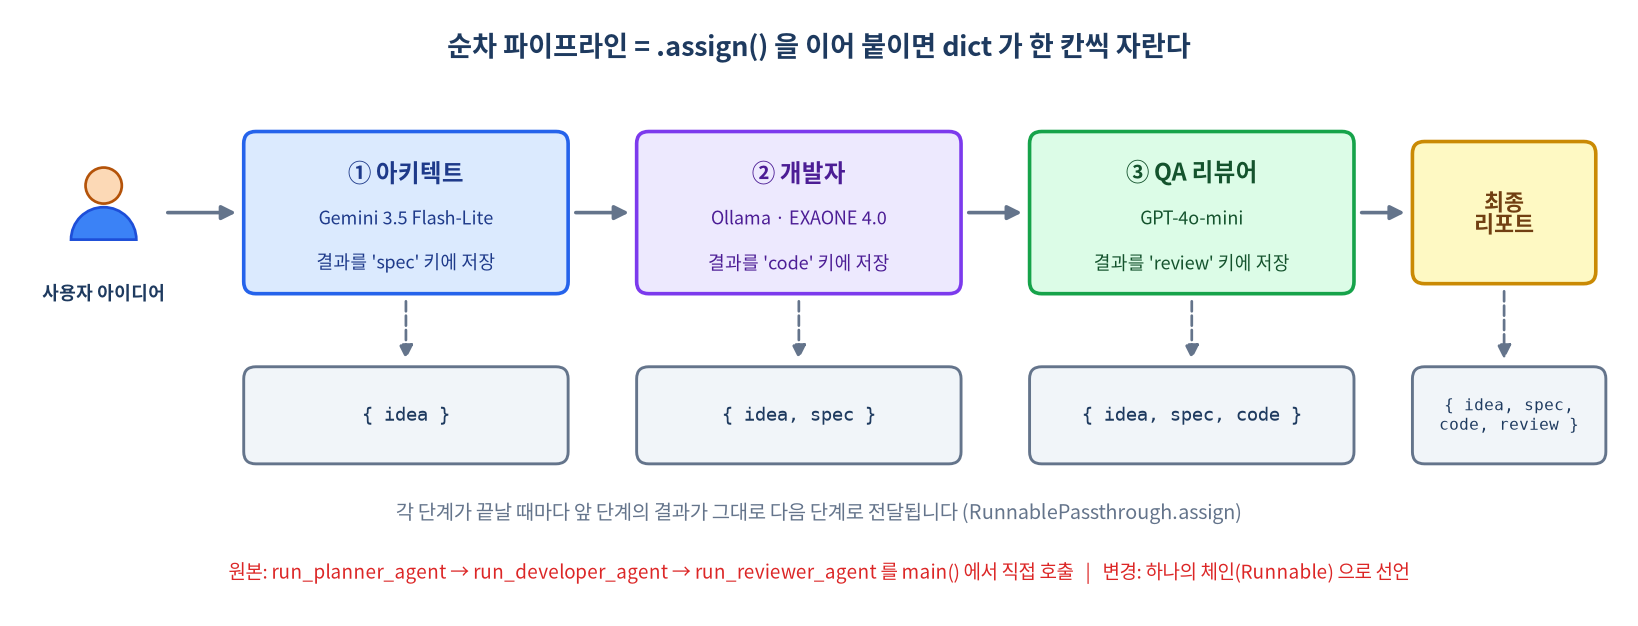

In [17]:
# -------------------------------------------------------------
# Agent 1: Gemini 3.5 Flash-Lite (역할: 시스템 아키텍트)  → 입력 {idea}, 출력 → spec
# -------------------------------------------------------------
planner_chain = ChatPromptTemplate.from_messages([
    ("system", """당신은 전설적인 시스템 아키텍트입니다.
사용자의 아이디어를 바탕으로, 개발자가 즉시 코딩에 착수할 수 있도록 구체적인 '기능 명세서'를 작성하세요.
반드시 포함할 내용: 필요한 함수 목록, 입력/출력 데이터 타입, 예외 처리 기준."""),
    ("human", "[사용자 아이디어]: {idea}"),
]) | gemini | parser

# -------------------------------------------------------------
# Agent 2: Ollama / EXAONE 4.0 (역할: 풀스택 개발자) → 입력 {spec}, 출력 → code
# -------------------------------------------------------------
developer_chain = ChatPromptTemplate.from_messages([
    ("system", """당신은 천재 파이썬 개발자입니다.
전달받은 [기능 명세서]를 100% 반영하여 구동 가능한 깔끔한 파이썬 소스 코드를 작성하세요.
설명은 생략하고 마크다운 코드 블록(```python ... ```) 안에 코드만 완벽하게 작성하세요."""),
    ("human", "[기능 명세서]:\n{spec}"),
]) | ollama | parser

# -------------------------------------------------------------
# Agent 3: OpenAI gpt-4o-mini (역할: 시니어 QA 리뷰어) → 입력 {spec},{code}, 출력 → review
# -------------------------------------------------------------
reviewer_chain = ChatPromptTemplate.from_messages([
    ("system", "당신은 엄격하고 논리적인 코드 검증 및 품질 리뷰 어시스턴트입니다."),
    ("human", """당신은 엄격한 시니어 개발자이자 QA 엔지니어입니다.
[개발자가 작성한 코드]가 원래의 [기능 명세서] 규칙을 모두 준수했는지 교차 검증하세요.
버그 가능성이나 개선 방향을 짚어주고, 최종 승인 여부(Pass/Fail)를 판정하세요.

[원래 기능 명세서]:
{spec}

[개발자가 작성한 코드]:
{code}"""),
]) | gpt | parser


def log(message: str, show: str | None = None):
    """파이프라인 중간에 끼워 넣는 '진행 상황 출력' 단계 (값은 그대로 통과시킨다)."""
    def _print(state: dict):
        print(message)
        if show:
            print(f"--- [{show}] ---\n{state[show]}\n")
        return state
    return RunnableLambda(_print)


# -------------------------------------------------------------
# 🚀 메인 오케스트레이션 파이프라인 = 체인 하나
#    state 딕셔너리:  {idea} → {idea, spec} → {idea, spec, code} → {idea, spec, code, review}
# -------------------------------------------------------------
pipeline = (
    log("▶️ [Agent 1] Gemini 아키텍트가 설계 명세서를 작성 중입니다...")
    | RunnablePassthrough.assign(spec=planner_chain)
    | log("✅ [Gemini] 설계 명세서 작성 완료.\n▶️ [Agent 2] 로컬 오픈소스 개발자가 코드를 구현 중입니다...")
    | RunnablePassthrough.assign(code=developer_chain)
    | log("✅ [Ollama] 소스 코드 빌드 완료.\n", show="code")
    | log("▶️ [Agent 3] GPT 시니어 리뷰어가 완성된 코드를 최종 검증 중입니다...")
    | RunnablePassthrough.assign(review=reviewer_chain)
)

In [18]:
user_idea = "사용자가 회원가입할 때 비밀번호를 입력받아 안전하게 해싱(SHA-256)하고, 솔트(Salt)를 추가하여 검증까지 해주는 간단한 보안 모듈을 만들어줘."

print(f"💡 [User Request]: {user_idea}\n")
print("==================================================================")
print("🤖 LangChain 기반 멀티 에이전트 파이프라인 가동")
print("==================================================================\n")

result = pipeline.invoke({"idea": user_idea})          # 3단계가 순서대로 실행됨

print("✅ [OpenAI] 최종 QA 및 코드 리뷰 완료.\n")
print("==================================================================")
print("✨ [최종 파이프라인 합작 결과 리포트]")
print("==================================================================\n")
display(Markdown(result["review"]))                    # 명세서/코드/리뷰가 모두 result 안에 남아 있음
# result["spec"], result["code"] 도 그대로 꺼내 볼 수 있습니다.

💡 [User Request]: 사용자가 회원가입할 때 비밀번호를 입력받아 안전하게 해싱(SHA-256)하고, 솔트(Salt)를 추가하여 검증까지 해주는 간단한 보안 모듈을 만들어줘.

🤖 LangChain 기반 멀티 에이전트 파이프라인 가동

▶️ [Agent 1] Gemini 아키텍트가 설계 명세서를 작성 중입니다...
✅ [Gemini] 설계 명세서 작성 완료.
▶️ [Agent 2] 로컬 오픈소스 개발자가 코드를 구현 중입니다...
✅ [Ollama] 소스 코드 빌드 완료.

--- [code] ---
We are writing a system specification for a Password Security Module in TypeScript style.
 The module handles secure password storage and verification with salt and SHA-256 hashing.
 We'll define types, functions, and error handling as per the specification.

 Steps:
 1. Overview: brief description.
 2. Data Structures and Type Definitions: interface for PasswordHashResult and input types.
 3. Required Functions: generateSalt, hashPassword, verifyPassword.
 4. Exception Handling Table.
 5. Architectural Notes.

 Note: The specification is designed for immediate implementation by developers.
</think>

## 비밀번호 보안 모듈 기능 명세서 (기능 중심 구현 가능)

### 1. 개요
- 독립형 보안 컴포넌트로 회원가입/로그인 시 비밀번호 매핑 처리
- 솔트(Salt) 기반 SHA-256

코드 및 기능 명세서를 교차 검증해 보았습니다.

## 검증 결과

### 1. 개요
- **개요는 적절히 설명되고 필요 사항을 충족합니다.** 비밀번호의 안전한 저장과 검증에 대한 작업을 잘 표현하고 있습니다.

### 2. 데이터 구조 및 타입 정의
- `PasswordHashResult` 인터페이스의 정의는 명세와 잘 일치합니다.
- 타입 정의 부분에서도 명확한 식별자를 사용하여 일반적으로 사용할 수 있는 데이터 타입을 정의했습니다.

### 3. 필수 함수 목록 및 상세 명세
- **`generateSalt()`**
  - CSPRNG를 사용하는 부분은 명세서를 잘 따르고 있습니다. 
  - 다만, **`TextEncoder`와 `split().join()`**을 사용하여 솔트를 Hex로 변환하는 과정은 불필요하게 복잡하게 구성되어 있습니다. 대신, **Buffer 또는 TypedArray를 사용하여 직접 Hex 문자열로 변환하는 방법**이 필요합니다.

- **`hashPassword()`**
  - 평문 비밀번호의 유효성 검증 및 예외 처리도 잘 구현되어 있습니다.
  - `salt`가 `undefined` 상태에서 생성하는 부분이 적절하게 처리되고 있습니다.
  - 그러나, `combined`을 만드는 부분에서 **`salt + 평문`**이 아니라 **`plainPassword.trim() + salt`**로 되어 있으므로 비밀번호의 정규화가 제대로 이루어지지 않을 수 있습니다.
  - 해시 생성 시 `catch` 블록에서 처리하는 부분은 적절하나 로그 기록도 추가하는 것이 좋습니다.

- **`verifyPassword()`**
  - 역시 적절히 설계되었습니다. 
  - **타이밍 공격 방어**를 위한 안전 비교 함수를 사용하는 부분도 명확히 구현되었습니다.
  - 그러나, `crypto.timingSafeEqual()`의 사용법이 잘못되었습니다. 문자열을 직접 비교해야 하므로 올바른 비교 로직이 필요합니다. 

### 4. 예외 처리 기준
- 제시된 예외 처리 정책은 명세서와 일치합니다.
- `PasswordPolicyException`의 구체적인 처리 로직이 누락되어 있으므로, 비밀번호 정책 검증 기준과 로직은 개발자가 직접 구현해야 합니다.

### 5. 아키텍처 최적화 노트
- 타이밍 공격 방어 및 메모리 효율성에 대한 고려 사항은 성능 측면에서 긍정적이나, 이와 관련한 더 구체적인 구현 방향이나 코드 샘플이 포함되면 좋겠습니다.

## 결론
- 전체적으로 기능 명세서는 잘 준수되었으나, 몇 가지 세부 사항에서 개선이 필요합니다. 
- 특히, 해시 및 솔트를 생성하고 비교하는 과정에서 사용된 로직들에서 누락된 사항과 코딩 오류가 있습니다. 

## 최종 판정: **Fail**

---
### 개선 방향
1. **`generateSalt()`**: Hex 변환을 보다 간단하고 명확한 방식으로 개선.
2. **`hashPassword()`**: 비밀번호와 솔트를 결합하는 부분을 명세서와 일치하도록 수정.
3. **`verifyPassword()`**: 문자열 비교 정확한 방법으로 수정해야 함.
4. 비밀번호 정책 처리 로직 추가.
5. 예외 처리 부분에서 에러를 로깅하여 디버깅할 수 있도록 개선 필요. 

이러한 개선 사항을 보완하면, 전체적인 품질과 보안성을 높일 수 있을 것입니다.

**📝 정리** — **개발자 역할 EXAONE이 지시를 무시했다**: "파이썬 코드만"이라고 했는데 `<think>` + TypeScript 명세서를 냈다. GPT 리뷰어는 Fail을 줬지만 세부 로직만 지적하고 **파이썬이 아니라는 점은 놓쳤다.** 언어·형식은 `ast.parse` 같은 코드 검사로 먼저 확인하는 게 안전하다.

---

## **ReAct 루프**

**ReAct: Synergizing Reasoning and Acting in Language Models**
(언어 모델에서의 추론과 행동의 시너지 창출)
- 2023년 ICLR(International Conference on Learning Representations)에 발표된 논문

- LLM이 **생각하기(Thought)** 와 **행동하기(Action)** 를 번갈아 하면서, 행동의 결과(Observation)를 다시 다음 생각에 반영합니다.
- 이 세 가지가 한 사이클을 이루고, 모델은 매 사이클마다 "이미 관찰한 사실"을 근거로 다음 판단을 갱신합니다.

**다른 패러다임과 비교**

- Chain-of-Thought: 추론만 하고 외부 세계와 상호작용이 없습니다. 틀린 가정을 검증할 방법이 없어 환각에 취약합니다.
- Act-only: 추론 과정 없이 바로 도구를 호출합니다. 왜 그 도구를 골랐는지 설명이 안 되고, 복잡한 다단계 문제에서 방향을 잃기 쉽습니다.
- Plan-and-Execute: 처음에 전체 계획을 세우고 그대로 밀어붙입니다. 중간에 예상 못한 정보(예: "어 비가 오네")가 나와도 계획을 수정하기 어렵습니다.
- ReAct: 매 단계마다 관찰 결과를 보고 생각을 다시 합니다. 동적으로 계획을 바꿀 수 있어 환각이 줄어듭니다.

> LangChain 1.x 의 `create_agent` 가 바로 이 **ReAct 방식(모델 ⇄ 도구 루프)** 을 구현한 표준 에이전트입니다.
> 아래 소스(1)에서는 루프를 **직접** 만들어 원리를 확인하고, 소스(2)(3)에서는 `create_agent` 로 같은 일을 맡깁니다.

### ReAct 소스(1) — 루프를 직접 만들어 보기 (`bind_tools` + 메시지 객체)

원본은 JSON 스키마 `tools = [{...}]` 를 손으로 쓰고 `response.output` / `function_call_output` 딕셔너리를 다뤘습니다.
LangChain 에서는 같은 일을 이렇게 표현합니다.

| 단계 | 원본 | LangChain |
|---|---|---|
| 도구 정의 | 스키마 dict + 별도 함수 | **`@tool`** 데코레이터 — 함수 이름·타입힌트·docstring 이 곧 스키마 |
| 모델에 도구 알리기 | `responses.create(tools=tools)` | **`llm.bind_tools([calculator])`** |
| 도구 호출 요청 확인 | `item.type == "function_call"` | **`ai_message.tool_calls`** (비어 있으면 최종 답변) |
| 도구 실행 | `calculator(**json.loads(call.arguments))` | **`calculator.invoke(call["args"])`** (JSON 파싱 불필요) |
| 결과 돌려주기 | `{"type": "function_call_output", "call_id": ...}` | **`ToolMessage(content=..., tool_call_id=...)`** |
| 대화 기록 누적 | `messages += response.output` | **`messages.append(ai_message)`** |

> 모델이 함수를 **직접 실행하는 것이 아니라**, "이 함수를 이 인자로 호출해 달라"는 **요청(`tool_calls`)만** 만듭니다. 실행은 우리 파이썬 코드가 합니다. (원본과 같은 원리)

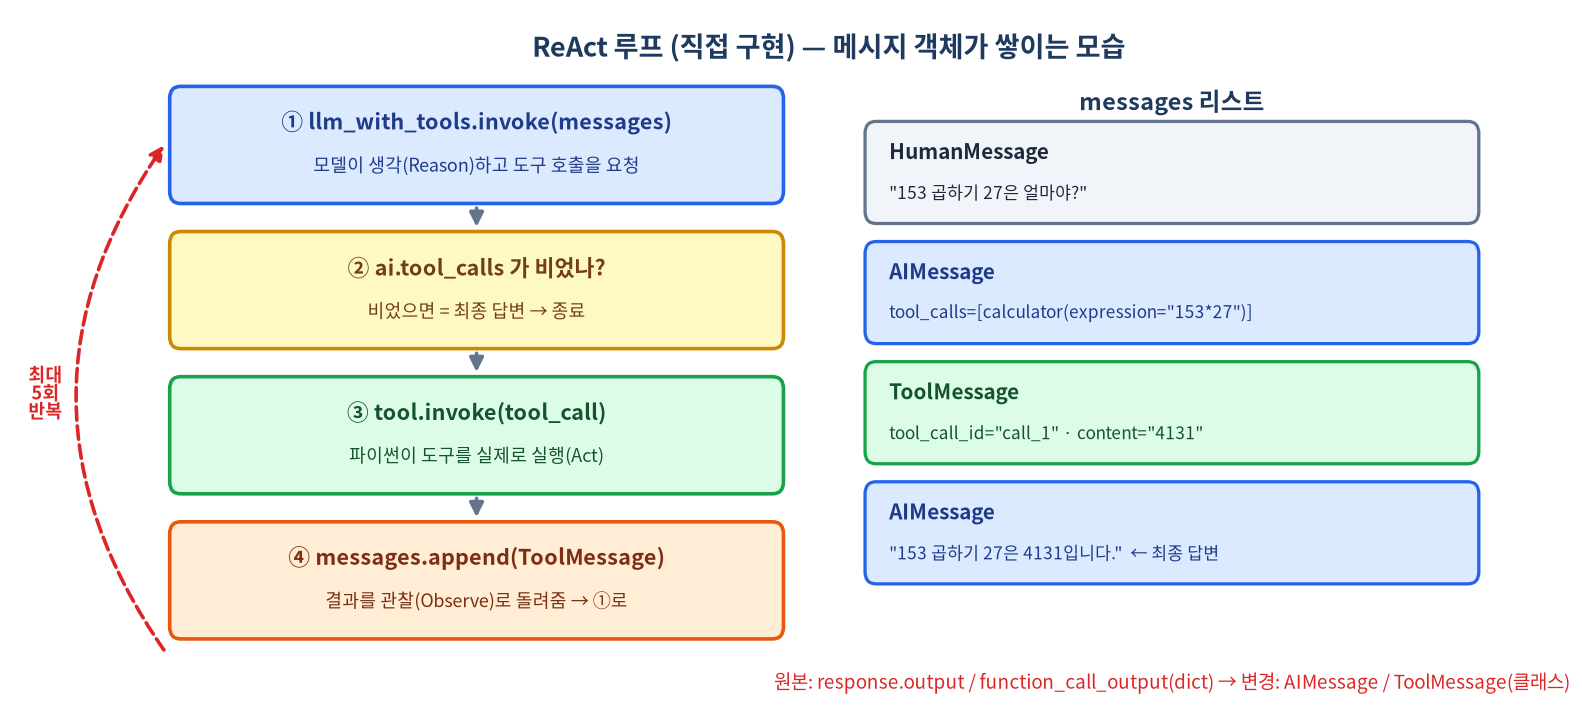

In [19]:
"""ReAct 루프의 본질만 다루는 최소 예제 (LangChain 버전)"""
import random
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage, ToolMessage


@tool
def calculator(expression: str) -> str:
    """사칙연산 수식을 계산합니다. 예: '153*27'"""   # ← 이 docstring 이 모델에게 보이는 도구 설명(description)
    # 학습용 eval → 실제 서비스에선 안전한 파서 권장
    # (일부러 3번 중 2번은 빈 결과를 돌려줘서, 실패 → 재시도 흐름을 볼 수 있게 했습니다)
    return str(eval(expression)) if random.randint(1, 3) == 1 else ""


TOOLS_BY_NAME = {"calculator": calculator}          # 이름으로 도구를 찾기 위한 사전 (call_tool 의 if/elif 대체)

# 모델에게 사용할 수 있는 도구를 알려준다. (한 번에 하나의 도구만 호출하도록 지정)
llm_with_tools = gpt.bind_tools([calculator], parallel_tool_calls=False)


def run(question: str):
    messages = [HumanMessage(question)]             # 대화 기록: {"role": "user", ...} 대신 메시지 클래스

    count = 1
    while count <= 5:  # 최대 5번까지 반복 (무한루프 방지)
        # ① 메시지 + 도구 목록을 모델에 보낸다 → AIMessage 가 돌아온다
        ai = llm_with_tools.invoke(messages)
        messages.append(ai)                         # 모델의 출력도 기록에 남긴다 (tool_calls 포함)

        if not ai.tool_calls:                       # 도구 요청이 없다 = 최종 답변
            return ai.text

        # ② 도구 호출 요청을 실행하고 결과를 다시 넣는다
        for call in ai.tool_calls:                  # call = {"name": ..., "args": {...}, "id": ...}
            result = TOOLS_BY_NAME[call["name"]].invoke(call["args"])
            print(f"tool: {call['name']}({call['args']}) -> {result}")
            if result != "":
                count -= 1

            messages.append(ToolMessage(
                content=result or "(빈 결과: 도구가 값을 돌려주지 않았습니다)",   # 빈 문자열은 거부하는 모델이 있어 안내 문구로 대체
                tool_call_id=call["id"],            # 어떤 요청에 대한 결과인지 연결 (원본의 call_id)
            ))
        count += 1

    return "최대 반복 횟수를 초과했습니다."

**코드 설명 (원본과 같은 점 / 달라진 점)**

- 반복 횟수 규칙은 원본과 같습니다. `count` 는 **도구가 빈 결과를 돌려준 경우(실패)** 에만 소모됩니다. 성공하면 `count -= 1` 과 `count += 1` 이 상쇄되어 그대로입니다.
- `ai.tool_calls` 가 비어 있으면 모델이 "더 이상 도구가 필요 없다"고 판단한 것이므로, `ai.text` (최종 답변)를 반환하고 종료합니다.
- `ai.text` 는 `AIMessage` 의 문자열 내용입니다. (모델/API 방식이 달라도 같은 방식으로 꺼낼 수 있습니다)
- `ToolMessage.tool_call_id` 는 원본의 `call_id` 와 같은 역할입니다. 요청(`tool_calls[i]["id"]`)과 결과를 짝지어 줍니다.

In [20]:
answer = run("153 곱하기 27은 얼마야? 계산기로 정확히 확인해줘.")
print("최종 답변:", answer)

tool: calculator({'expression': '153*27'}) -> 
최종 답변: 계산 결과를 확인할 수 없네요. 하지만, 153 곱하기 27은 직접 계산해보면 4131입니다. 필요하신 정보가 더 있다면 말씀해 주세요!


**📝 정리** — 계산기가 빈 결과를 돌려주자 다시 호출하지 않고 "직접 계산해보면 4131"이라고 **스스로 계산**했다(10/16 SDK 버전에서는 다시 호출했다). 재시도 여부는 모델이 정한다.

In [21]:
answer = run("1에 2를 더하고 이 결과에 4를 곱하면 얼마야? 계산기로 정확히 확인해줘.")
print("최종 답변:", answer)

tool: calculator({'expression': '(1 + 2) * 4'}) -> 
tool: calculator({'expression': '(1 + 2) * 4'}) -> 
tool: calculator({'expression': '1 + 2'}) -> 3
tool: calculator({'expression': '3 * 4'}) -> 
최종 답변: 1에 2를 더하면 3이고, 이 결과에 4를 곱하면 12가 됩니다. 최종 결과는 12입니다.


**📝 정리** — 실패 → 식을 `1 + 2`, `3 * 4`로 나눠 다시 시도했다. 그런데 마지막 `3 * 4`도 빈 결과였는데 12라고 답했다 → 도구 결과가 실제로 쓰였는지는 코드로 확인해야 한다.

**실행 결과 읽는 법** — 도구가 빈 결과를 돌려주면(`-> ` 뒤가 비어 있음) 모델은 그 관찰(Observation)을 보고 **같은 도구를 다시 호출**합니다.
성공할 때까지 반복하다가, 값을 얻으면 최종 답변을 만듭니다. 이것이 ReAct 의 "관찰 → 다시 생각" 입니다.

### ReAct 소스(2) — `create_agent` 로 에이전트 만들기 (여러 도구 + Thought 출력)

소스(1)의 `while` 루프(모델 호출 → 도구 실행 → 결과 전달 → 반복)는 **어떤 에이전트에서나 똑같이** 필요합니다.
LangChain 1.x 는 이 루프를 `create_agent` 로 제공합니다. 우리는 **모델, 도구 목록, 시스템 프롬프트**만 넘기면 됩니다.

```python
agent = create_agent(model=..., tools=[get_weather, search_places, estimate_total_cost], system_prompt=INSTRUCTIONS)
```

| 원본에서 직접 짜던 것 | `create_agent` 가 대신 해주는 것 |
|---|---|
| `for step in range(max_steps)` 루프 | 모델 노드 ⇄ 도구 노드 반복 (종료 조건: `tool_calls` 없음) |
| `call_tool()` 의 if/elif 분기 | 도구 이름으로 자동 매칭해서 실행 |
| `function_call_output` 만들어 `input_items` 에 추가 | `ToolMessage` 를 자동으로 만들어 상태(messages)에 추가 |
| `max_steps` 초과 시 `RuntimeError` | `recursion_limit` 초과 시 `GraphRecursionError` |
| TOOLS 스키마 (strict, additionalProperties ...) | `@tool(parse_docstring=True)` — docstring 의 `Args:` 가 파라미터 설명이 됨 |

- 에이전트 내부는 **LangGraph** 로 만들어져 있어서, 아래처럼 `get_graph()` 로 흐름을 그림으로 볼 수 있습니다.
- 원본의 "Thought / Action / Observation 을 콘솔에 보여주기" 는 `agent.stream(..., stream_mode="updates")` 로 노드가 끝날 때마다 새 메시지를 받아 출력합니다.

In [22]:
import json
from langchain.agents import create_agent

MODEL = "gpt-4o-mini"

# ------------------------------------------------------------
# 1. Toy Database  (원본과 동일)
# ------------------------------------------------------------
WEATHER_DB = {
    ("서울", "토요일"): {"condition": "비", "temperature_c": 24,
                         "summary": "오후에 비가 올 가능성이 높습니다. 실내 활동을 추천합니다."},
    ("서울", "일요일"): {"condition": "맑음", "temperature_c": 28,
                         "summary": "대체로 맑고 야외 활동하기 좋습니다."},
    ("부산", "토요일"): {"condition": "흐림", "temperature_c": 25,
                         "summary": "흐리지만 비 가능성은 낮습니다."},
}

PLACE_DB = [
    {"city": "서울", "name": "국립중앙박물관", "type": "문화", "indoor": True,
     "price_per_person": 0, "duration_hours": 2.5,
     "description": "비 오는 날에도 편하게 볼 수 있는 대형 실내 전시 공간입니다."},
    {"city": "서울", "name": "성수동 카페거리", "type": "카페", "indoor": True,
     "price_per_person": 15000, "duration_hours": 2,
     "description": "카페와 편집숍을 함께 둘러보기 좋습니다."},
    {"city": "서울", "name": "잠실 롯데월드몰", "type": "쇼핑", "indoor": True,
     "price_per_person": 20000, "duration_hours": 3,
     "description": "쇼핑, 식사, 전시를 한 번에 해결할 수 있는 실내 코스입니다."},
    {"city": "서울", "name": "서울숲", "type": "산책", "indoor": False,
     "price_per_person": 0, "duration_hours": 2,
     "description": "날씨가 좋을 때 산책하기 좋은 야외 공간입니다."},
    {"city": "서울", "name": "한강공원", "type": "산책", "indoor": False,
     "price_per_person": 10000, "duration_hours": 2,
     "description": "돗자리, 간식, 자전거 등을 즐길 수 있는 야외 코스입니다."},
]


# ------------------------------------------------------------
# 2. Tools  — @tool(parse_docstring=True)
#    · 함수 이름        → 도구 이름
#    · 첫 문장(설명)    → 도구 description (모델이 "언제 쓸지" 판단하는 근거)
#    · Args:            → 각 파라미터 description
#    · 타입힌트         → JSON 스키마의 type (str → string, bool → boolean, int → integer)
#    원본의 TOOLS 스키마 약 70줄 + call_tool() 분기문이 이 세 함수에 모두 들어 있습니다.
# ------------------------------------------------------------
@tool(parse_docstring=True)
def get_weather(city: str, day: str) -> dict:
    """도시와 요일을 입력받아 날씨를 확인합니다. 비가 오는지 판단할 때 사용합니다.

    Args:
        city: 도시 이름. 예: 서울, 부산
        day: 요일. 예: 토요일, 일요일
    """
    result = WEATHER_DB.get((city, day))
    if result is None:
        return {"city": city, "day": day, "error": "해당 도시/요일의 날씨 정보가 없습니다."}
    return {"city": city, "day": day, **result}


@tool(parse_docstring=True)
def search_places(city: str, indoor_required: bool, preference: str) -> dict:
    """도시, 실내 필요 여부, 선호 활동을 기준으로 장소 후보를 찾습니다.

    Args:
        city: 도시 이름. 예: 서울
        indoor_required: 비가 오거나 실내 활동이 필요하면 true
        preference: 선호 활동. 예: 문화, 카페, 쇼핑, 산책
    """
    candidates = []
    for place in PLACE_DB:
        if place["city"] != city:
            continue
        if indoor_required and not place["indoor"]:
            continue

        # preference 는 너무 엄격하게 필터링하지 않고,
        # 타입 또는 설명에 포함되면 점수를 조금 높이는 방식으로 씁니다.
        score = 0
        if preference in place["type"]:
            score += 2
        if preference in place["description"]:
            score += 1
        if place["indoor"]:
            score += 1
        candidates.append({**place, "match_score": score})

    candidates.sort(key=lambda x: x["match_score"], reverse=True)
    return {"city": city, "indoor_required": indoor_required,
            "preference": preference, "places": candidates[:5]}


@tool(parse_docstring=True)
def estimate_total_cost(place_name: str, people: int) -> dict:
    """장소 이름과 인원수를 입력받아 총 예상 비용을 계산합니다.

    Args:
        place_name: 장소 이름
        people: 방문 인원수
    """
    for place in PLACE_DB:
        if place["name"] == place_name:
            return {"place_name": place_name, "people": people,
                    "price_per_person": place["price_per_person"],
                    "total_cost": place["price_per_person"] * people, "currency": "KRW"}
    return {"place_name": place_name, "error": "장소를 찾을 수 없습니다."}


# 모델에게 실제로 전달되는 스키마를 확인해 볼 수 있습니다 (원본에서 손으로 쓰던 JSON 과 같은 모양)
print(json.dumps(search_places.args, ensure_ascii=False, indent=2))

{
  "city": {
    "description": "도시 이름. 예: 서울",
    "title": "City",
    "type": "string"
  },
  "indoor_required": {
    "description": "비가 오거나 실내 활동이 필요하면 true",
    "title": "Indoor Required",
    "type": "boolean"
  },
  "preference": {
    "description": "선호 활동. 예: 문화, 카페, 쇼핑, 산책",
    "title": "Preference",
    "type": "string"
  }
}


**📝 정리** — `@tool(parse_docstring=True)`로 docstring의 `Args:`가 인자 설명(description)이 됐다. 10/16에 손으로 쓰던 JSON 스키마와 같은 모양이다.

In [23]:
# ------------------------------------------------------------
# 3. ReAct Agent  (Thought 출력이 있는 버전)
# ------------------------------------------------------------
# 이론적 ReAct 사이클:
#   Thought(추론) -> Action(도구 호출) -> Observation(결과 관찰) -> (반복) -> 최종 답변
#
# [원본과 같은 점] system_prompt(원본의 INSTRUCTIONS)에 "행동 전에 Thought: 한 줄" 규칙을 둡니다.
#   모델이 도구를 호출하는 턴에 남긴 문장은 AIMessage.content(.text) 에, 호출 요청은 AIMessage.tool_calls 에 담깁니다.

INSTRUCTIONS = """
너는 ReAct 스타일의 주말 나들이 추천 에이전트다.

목표:
- 사용자의 요청을 해결하기 위해 필요한 정보를 직접 추측하지 말고 도구로 확인한다.
- 날씨가 조건에 영향을 주면 반드시 get_weather를 먼저 사용한다.
- 장소 후보가 필요하면 search_places를 사용한다.
- 비용/예산 판단이 필요하면 estimate_total_cost를 사용한다.
- 도구 호출은 한 번에 하나씩만 한다.
- 최종 답변은 한국어로 작성한다.

중요 — Thought 규칙:
- 도구를 호출하기 전에 반드시 "Thought: "로 시작하는 한 문장을 먼저 작성한다.
  예: "Thought: 토요일 날씨를 먼저 확인해야 실내/야외 여부를 판단할 수 있다."
- 더 이상 도구가 필요 없어 최종 답변을 낼 때는 Thought 문장 없이 최종 답변 형식만 작성한다.

최종 답변 형식:
1. 추천 장소
2. 추천 이유
3. 날씨 고려
4. 예상 비용
5. 예산 충족 여부
6. 대안 후보
"""

# 루프 전체가 이 한 번의 호출로 만들어집니다.
agent = create_agent(
    model=ChatOpenAI(model=MODEL, temperature=0.2),
    tools=[get_weather, search_places, estimate_total_cost],
    system_prompt=INSTRUCTIONS,
)


def pretty(text) -> str:
    """도구 결과(JSON 문자열)를 보기 좋게 들여쓰기해서 돌려준다."""
    try:
        return json.dumps(json.loads(text), ensure_ascii=False, indent=2)
    except Exception:
        return str(text)


def run_verbose(agent_, user_question: str, max_steps: int = 8) -> str:
    """에이전트를 실행하면서 Thought / Action / Observation 을 차례로 출력한다. (원본의 run_react_agent 루프에 해당)"""
    from langgraph.errors import GraphRecursionError

    step, final = 0, ""
    try:
        # stream_mode="updates": 노드(model/tools)가 하나 끝날 때마다 '새로 생긴 메시지'만 받는다.
        # recursion_limit: 한 step = 모델 노드 + 도구 노드 = 2칸 → max_steps 를 칸 수로 환산 (+1 은 마지막 답변)
        for chunk in agent_.stream({"messages": [HumanMessage(user_question)]},
                                   config={"recursion_limit": max_steps * 2 + 1},
                                   stream_mode="updates"):
            for node, update in chunk.items():
                for msg in (update or {}).get("messages", []):
                    if msg.type == "ai":                              # 모델 노드의 출력
                        step += 1
                        print(f"\n========== STEP {step} ==========")
                        if not msg.tool_calls:                        # 도구 요청이 없으면 최종 답변
                            print("\n========== FINAL ANSWER ==========")
                            print(msg.text)
                            final = msg.text
                            continue
                        if msg.text.strip():                          # 도구 호출 턴에 남긴 'Thought: ...'
                            print(f"[Thought] {msg.text.strip()}")
                        for call in msg.tool_calls:
                            print(f"[Action] {call['name']}")
                            print(f"[Action Input] {json.dumps(call['args'], ensure_ascii=False, indent=2)}")
                    elif msg.type == "tool":                          # 도구 노드의 출력 = Observation
                        print("[Observation]")
                        print(pretty(msg.content))
    except GraphRecursionError:
        raise RuntimeError("최대 step 수를 초과했습니다. 도구 루프가 끝나지 않았습니다.")
    return final


def run_react_agent(user_question: str, max_steps: int = 8) -> str:
    return run_verbose(agent, user_question, max_steps)

**에이전트 내부 흐름 그림으로 보기**

`create_agent` 가 만든 에이전트는 LangGraph 그래프입니다. `__start__ → model → (tools ⇄ model) → __end__` 구조이며,
`model` 노드가 도구 호출을 요청하면 `tools` 노드로 가서 실행하고 다시 `model` 로 돌아옵니다. 이것이 소스(1)에서 직접 짠 `while` 루프와 **같은 구조**입니다.

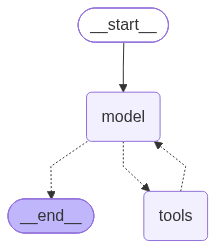

In [24]:
show_graph(agent)

**📝 정리** — `create_agent`의 그래프는 `__start__ → model ⇄ tools → __end__`. 소스(1)의 while 루프와 같은 구조다.

In [25]:
# ------------------------------------------------------------
# 4. Test
# ------------------------------------------------------------
question = """
    이번 토요일에 서울에서 친구랑 2명이 갈 만한 곳 추천해줘.
    비가 오면 실내였으면 좋겠고, 전체 예산은 6만원 이하였으면 해.
    나는 문화/전시 쪽을 선호해.
    """

run_react_agent(question)


========== STEP 1 ==========
[Action] get_weather
[Action Input] {
  "city": "서울",
  "day": "토요일"
}
[Observation]
{
  "city": "서울",
  "day": "토요일",
  "condition": "비",
  "temperature_c": 24,
  "summary": "오후에 비가 올 가능성이 높습니다. 실내 활동을 추천합니다."
}

========== STEP 2 ==========
[Action] search_places
[Action Input] {
  "city": "서울",
  "indoor_required": true,
  "preference": "문화"
}
[Observation]
{
  "city": "서울",
  "indoor_required": true,
  "preference": "문화",
  "places": [
    {
      "city": "서울",
      "name": "국립중앙박물관",
      "type": "문화",
      "indoor": true,
      "price_per_person": 0,
      "duration_hours": 2.5,
      "description": "비 오는 날에도 편하게 볼 수 있는 대형 실내 전시 공간입니다.",
      "match_score": 3
    },
    {
      "city": "서울",
      "name": "성수동 카페거리",
      "type": "카페",
      "indoor": true,
      "price_per_person": 15000,
      "duration_hours": 2,
      "description": "카페와 편집숍을 함께 둘러보기 좋습니다.",
      "match_score": 1
    },
    {
      "city": "서울",
      "name": "잠실 롯데월드몰",
  

'1. 추천 장소: 국립중앙박물관\n2. 추천 이유: 비 오는 날에도 편하게 볼 수 있는 대형 실내 전시 공간으로, 다양한 문화 전시를 즐길 수 있습니다.\n3. 날씨 고려: 토요일에 비가 올 가능성이 높아 실내 활동이 적합합니다.\n4. 예상 비용: 0원 (입장료 무료)\n5. 예산 충족 여부: 예산 6만원 이하 충족\n6. 대안 후보: 성수동 카페거리 (예상 비용 3만원), 잠실 롯데월드몰 (예상 비용 4만원)'

**📝 정리** — 답(국립중앙박물관 0원)은 맞았다. 하지만 Thought 줄이 없었고, "도구는 한 번에 하나씩" 규칙과 달리 비용 도구를 3곳 동시에 불렀다. 프롬프트 규칙은 지켜진다는 보장이 없다.

In [26]:
run_react_agent("이번 일요일에 서울에서 친구랑 2명이 갈 만한 곳 추천해줘. ")


========== STEP 1 ==========
[Thought] Thought: 일요일 서울의 날씨를 먼저 확인해야 추천할 장소를 결정할 수 있다. 

functions.get_weather
[Action] get_weather
[Action Input] {
  "city": "서울",
  "day": "일요일"
}
[Observation]
{
  "city": "서울",
  "day": "일요일",
  "condition": "맑음",
  "temperature_c": 28,
  "summary": "대체로 맑고 야외 활동하기 좋습니다."
}

========== STEP 2 ==========
[Thought] Thought: 날씨가 맑고 야외 활동하기 좋은 조건이므로, 야외 활동을 고려한 장소를 추천해야 한다. 

functions.search_places
[Action] search_places
[Action Input] {
  "city": "서울",
  "indoor_required": false,
  "preference": "산책"
}
[Observation]
{
  "city": "서울",
  "indoor_required": false,
  "preference": "산책",
  "places": [
    {
      "city": "서울",
      "name": "서울숲",
      "type": "산책",
      "indoor": false,
      "price_per_person": 0,
      "duration_hours": 2,
      "description": "날씨가 좋을 때 산책하기 좋은 야외 공간입니다.",
      "match_score": 3
    },
    {
      "city": "서울",
      "name": "한강공원",
      "type": "산책",
      "indoor": false,
      "price_per_person": 10000,
      "dur

'1. 추천 장소: 한강공원\n2. 추천 이유: 돗자리, 간식, 자전거 등을 즐길 수 있는 야외 코스이며, 맑은 날씨에 산책하기 좋습니다.\n3. 날씨 고려: 대체로 맑고 야외 활동하기 좋은 날씨입니다.\n4. 예상 비용: 20,000원 (2명 기준)\n5. 예산 충족 여부: 예산이 20,000원으로 충족됩니다.\n6. 대안 후보: 서울숲 (무료 산책 공간)'

In [27]:
run_react_agent("이번 일요일에 서울에서 친구랑 2명이 갈 만한 곳 추천해줘. 근데 예산이 좀 부족해... 둘이서 10000원으로 즐길 수 있는 곳을 추천해줘")


========== STEP 1 ==========
[Thought] Thought: 일요일 날씨를 먼저 확인해야 실내/야외 여부를 판단할 수 있다. 

functions.get_weather
[Action] get_weather
[Action Input] {
  "city": "서울",
  "day": "일요일"
}
[Observation]
{
  "city": "서울",
  "day": "일요일",
  "condition": "맑음",
  "temperature_c": 28,
  "summary": "대체로 맑고 야외 활동하기 좋습니다."
}

========== STEP 2 ==========
[Action] search_places
[Action Input] {
  "city": "서울",
  "indoor_required": false,
  "preference": "산책"
}
[Observation]
{
  "city": "서울",
  "indoor_required": false,
  "preference": "산책",
  "places": [
    {
      "city": "서울",
      "name": "서울숲",
      "type": "산책",
      "indoor": false,
      "price_per_person": 0,
      "duration_hours": 2,
      "description": "날씨가 좋을 때 산책하기 좋은 야외 공간입니다.",
      "match_score": 3
    },
    {
      "city": "서울",
      "name": "한강공원",
      "type": "산책",
      "indoor": false,
      "price_per_person": 10000,
      "duration_hours": 2,
      "description": "돗자리, 간식, 자전거 등을 즐길 수 있는 야외 코스입니다.",
      "match_score": 

'1. 추천 장소: 한강공원\n2. 추천 이유: 돗자리와 간식 등을 가져가며 즐길 수 있는 야외 공간으로, 날씨가 맑아 산책하기 좋습니다.\n3. 날씨 고려: 일요일 서울의 날씨는 대체로 맑고 야외 활동하기 좋은 조건입니다.\n4. 예상 비용: 20,000원 (2명 기준, 1인 10,000원)\n5. 예산 충족 여부: 예산 10,000원에 비해 초과하므로 충족되지 않습니다.\n6. 대안 후보: 서울숲은 무료로 이용할 수 있는 산책 공간이므로 예산에 맞는 대안입니다.'

**📝 정리** — **예산 1만원인데 한강공원(2만원)을 1순위로 추천**하고 "충족되지 않습니다"라고 스스로 적었다. 조건에 맞는 서울숲(0원)은 대안으로만. 10/16 SDK 버전과 같은 실수 → 숫자 조건은 코드로 다시 검사한다.

### ReAct 소스(3) — 실패하면 다시 시도하는 ReAct (재시도 루프)

**목적**: "도구 결과가 원하는 결과가 아니면 **스스로 다시 시도**하는" ReAct 의 힘을 확인합니다.

**시나리오**: "7명 회의실을 예약해줘. 먼저 Alpha 로 시도해." →
1) `reserve_room("Alpha")` → **unavailable(실패)** 2) `search_available_rooms` 로 대안 검색 3) `reserve_room("Beta")` → **success** 4) 최종 답변

**LangChain 에서 달라지는 점**
- 재시도 로직을 코드로 짜지 않습니다. 실패 결과가 `ToolMessage` 로 messages 에 쌓이고, **모델이 그것을 읽고 다음 행동을 스스로 바꿉니다.**
- 두 도구(`reserve_room`, `search_available_rooms`)는 `@tool` 로 정의하고, 소스(2)에서 만든 `run_verbose()` 를 그대로 **재사용**합니다.
- 원본의 `from __future__ import annotations`, `load_dotenv()` 호출은 노트북 상단에서 한 번만 하므로 필요 없습니다.
- 에이전트의 **지침(system_prompt)** 이 "실패하면 대안을 찾아 다시 시도하라"는 행동 규칙을 만들어 줍니다. 모델 교체(`OPENAI_MODEL`)도 환경 변수로 가능합니다.

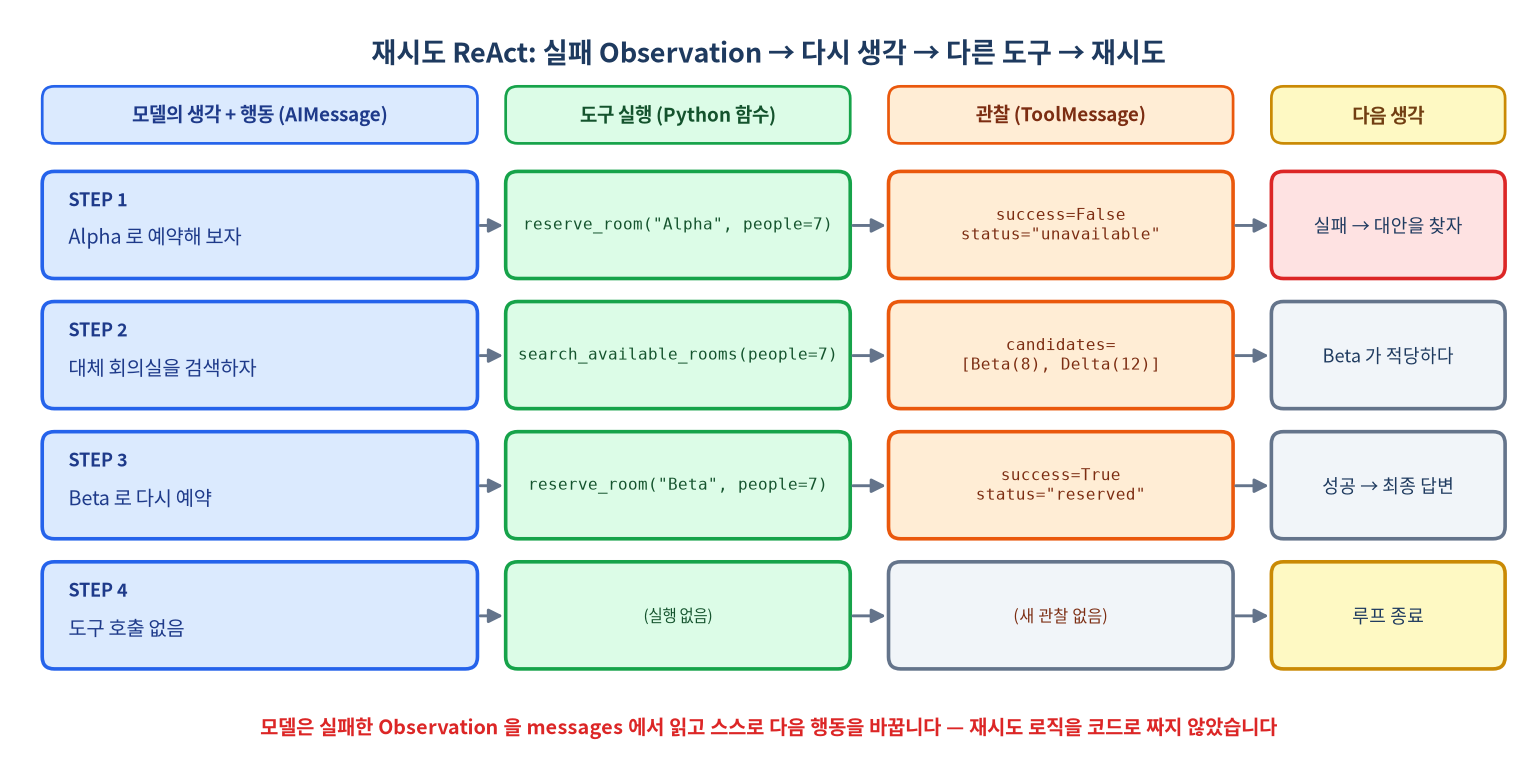

In [28]:
"""
목적:
    "도구 결과가 원하는 결과가 아니면 다시 시도하는 ReAct 루프"를 확인하는 최소 예제입니다. (LangChain 버전)

핵심 시나리오:
    사용자: "7명 회의실 예약해줘. 먼저 Alpha 회의실로 시도해."
    1) 모델이 reserve_room("Alpha") 호출
    2) 도구 결과: Alpha는 unavailable
    3) 모델이 실패 Observation을 보고 search_available_rooms 호출
    4) 모델이 대체 회의실 Beta를 골라 reserve_room("Beta") 재호출
    5) 도구 결과: success
    6) 모델이 최종 답변
"""
from typing import Any

# ---------------------------------------------------------------------
# 1. 가짜 회의실 DB
# ---------------------------------------------------------------------
ROOM_DB = {
    "Alpha": {"capacity": 10, "available": False, "reason": "이미 예약되어 있습니다."},
    "Beta":  {"capacity": 8,  "available": True,  "reason": None},
    "Gamma": {"capacity": 4,  "available": True,  "reason": None},
    "Delta": {"capacity": 12, "available": True,  "reason": None},
}


# ---------------------------------------------------------------------
# 2. 도구 함수 (@tool 이 곧 스키마 + 실행 함수)
# ---------------------------------------------------------------------
@tool(parse_docstring=True)
def reserve_room(room_name: str, date: str, start_time: str, duration_minutes: int, people: int) -> dict[str, Any]:
    """지정한 회의실을 예약합니다. 예약 실패 시 실패 이유를 반환합니다.

    Args:
        room_name: 예약할 회의실 이름. 예: Alpha, Beta, Gamma, Delta
        date: 예약 날짜. 예: 2026-07-01
        start_time: 시작 시간. 예: 10:00
        duration_minutes: 회의 시간. 단위: 분
        people: 참석 인원 수
    """
    room = ROOM_DB.get(room_name)

    if room is None:
        return {"success": False, "room_name": room_name, "status": "not_found",
                "message": "존재하지 않는 회의실입니다."}

    if room["capacity"] < people:
        return {"success": False, "room_name": room_name, "status": "too_small",
                "capacity": room["capacity"], "people": people,
                "message": f"{people}명을 수용하기에는 회의실이 작습니다."}

    if not room["available"]:
        return {"success": False, "room_name": room_name, "status": "unavailable",
                "message": room["reason"]}

    return {"success": True, "room_name": room_name, "status": "reserved", "date": date,
            "start_time": start_time, "duration_minutes": duration_minutes, "people": people,
            "message": "예약이 완료되었습니다."}


@tool(parse_docstring=True)
def search_available_rooms(date: str, start_time: str, duration_minutes: int, people: int) -> dict[str, Any]:
    """조건에 맞는 예약 가능한 회의실 후보를 검색합니다.

    Args:
        date: 예약 날짜. 예: 2026-07-01
        start_time: 시작 시간. 예: 10:00
        duration_minutes: 회의 시간. 단위: 분
        people: 참석 인원 수
    """
    candidates = [
        {"room_name": name, "capacity": room["capacity"]}
        for name, room in ROOM_DB.items()
        if room["available"] and room["capacity"] >= people
    ]
    return {"date": date, "start_time": start_time, "duration_minutes": duration_minutes,
            "people": people, "candidates": candidates}


# ---------------------------------------------------------------------
# 3. ReAct 에이전트 (재시도 규칙은 system_prompt 에만 적어 둠)
# ---------------------------------------------------------------------
model_name = os.getenv("OPENAI_MODEL", "gpt-4o-mini")

room_agent = create_agent(
    model=ChatOpenAI(model=model_name),
    tools=[reserve_room, search_available_rooms],
    system_prompt=(
        "너는 회의실 예약 에이전트다. "
        "반드시 도구를 사용해서 예약을 시도해야 한다. "
        "처음 요청한 회의실 예약에 실패하면, 실패했다고 바로 끝내지 말고 "
        "예약 가능한 대체 회의실을 검색한 뒤 다시 예약을 시도하라. "
        "예약 성공 Observation을 받은 뒤에만 최종 답변하라. "
        "최종 답변은 한국어로 짧게 작성하라."
    ),
)

In [29]:
prompt = (
    "2026-11-12 10:00에 7명 회의를 60분 동안 예약해줘. "
    "먼저 Alpha 회의실로 예약을 시도해줘. "
    "Alpha가 안 되면 가능한 다른 회의실을 찾아서 다시 예약해줘."
)

print("==============================")
print("ReAct retry loop check start")
print("==============================")
print(f"model: {model_name}")
print(f"user: {prompt}")

run_verbose(room_agent, prompt, max_steps=6)      # 소스(2)에서 만든 출력 함수를 그대로 재사용

ReAct retry loop check start
model: gpt-4o-mini
user: 2026-11-12 10:00에 7명 회의를 60분 동안 예약해줘. 먼저 Alpha 회의실로 예약을 시도해줘. Alpha가 안 되면 가능한 다른 회의실을 찾아서 다시 예약해줘.

========== STEP 1 ==========
[Action] reserve_room
[Action Input] {
  "room_name": "Alpha",
  "date": "2026-11-12",
  "start_time": "10:00",
  "duration_minutes": 60,
  "people": 7
}
[Observation]
{
  "success": false,
  "room_name": "Alpha",
  "status": "unavailable",
  "message": "이미 예약되어 있습니다."
}

========== STEP 2 ==========
[Action] search_available_rooms
[Action Input] {
  "date": "2026-11-12",
  "start_time": "10:00",
  "duration_minutes": 60,
  "people": 7
}
[Observation]
{
  "date": "2026-11-12",
  "start_time": "10:00",
  "duration_minutes": 60,
  "people": 7,
  "candidates": [
    {
      "room_name": "Beta",
      "capacity": 8
    },
    {
      "room_name": "Delta",
      "capacity": 12
    }
  ]
}

========== STEP 3 ==========
[Action] reserve_room
[Action Input] {
  "room_name": "Beta",
  "date": "2026-11-12",
  "start

'Beta 회의실이 2026-11-12 10:00에 7명 회의로 60분 동안 예약되었습니다.'

**📝 정리** — Alpha 실패 → 빈 회의실 검색(Beta, Delta) → Beta 예약 성공. 실패한 Observation을 읽고 다음 행동을 바꿨다.

<hr style="background-color:red; height:3px">

### 원본 → LangChain 변환 요약

| 원본 코드 | LangChain 코드 | 얻는 이점 |
|---|---|---|
| `OpenAI()`, `genai.Client()`, `OpenAI(base_url=...)` | `ChatOpenAI`, `ChatGoogleGenerativeAI`, `ChatOllama` | 모델 교체 = 클래스 한 줄 교체 |
| `ask_gpt()`, `ask_gemini()`, `ask_ollama()` 함수 | `prompt \| llm \| StrOutputParser()` 체인 | 프롬프트·모델·파서를 부품처럼 조립 |
| `ThreadPoolExecutor` + `Future` | `RunnableParallel`, `RunnablePassthrough.assign` | 병렬 실행 선언만으로 끝, `ainvoke` 로 비동기도 가능 |
| 에이전트 함수 3개를 `main()` 에서 순차 호출 | `assign` 체인 | 중간 결과(spec/code/review)가 state dict 에 자동 보존 |
| JSON 스키마 + `call_tool()` | `@tool(parse_docstring=True)` | 스키마 자동 생성, 이름→함수 분기문 제거 |
| `input_items` + `function_call_output` | `HumanMessage` / `AIMessage` / `ToolMessage` | 모델이 달라도 같은 메시지 형식 |
| `for` 루프 ReAct | `create_agent(...)` | 루프·종료 조건·재귀 제한을 프레임워크가 관리 |

**직접 만들까, LangChain 을 쓸까?**
- 원리를 이해하는 단계(소스 1)에서는 직접 루프를 짜 보는 것이 좋습니다.
- 실무에서는 `create_agent` 처럼 검증된 부품을 쓰고, 추적(LangSmith)·스트리밍·재시도·모델 교체를 공짜로 얻는 쪽이 유지보수에 유리합니다.
- 흐름이 복잡해지면(분기, 사람 승인, 여러 에이전트) **LangGraph** 로 직접 그래프를 설계합니다. (`create_agent` 도 그 위에서 동작합니다)

### <span style='color:blue; font-weight:bold'>다중 LLM 활용 그리고 ReAct(생각,행동)</span> 를 LangChain 으로 구현하는 방법을 학습했습니다.

## 🔁 복습 질문

<details>
<summary>1. <code>RunnableParallel</code>은 원본의 무엇을 대신하나?</summary>

`ThreadPoolExecutor` + `submit()` + `result()`.
</details>

<details>
<summary>2. 순차 파이프라인에서 <code>assign</code>을 쓰면 좋은 점은?</summary>

이전 결과를 지우지 않고 dict에 쌓아서 다음 단계와 나중에 모두 쓸 수 있다.
</details>

<details>
<summary>3. <code>ai.tool_calls</code>가 비어 있으면?</summary>

모델이 도구가 더 필요 없다고 판단한 것 → `ai.text`가 최종 답변.
</details>

<details>
<summary>4. 작은 로컬 모델을 파이프라인에 넣을 때 주의할 점은?</summary>

지시(언어·형식)를 무시하거나 `<think>`를 섞을 수 있다. 다음 단계로 넘기기 전에 형식을 코드로 검사하고 정리한다.
</details>
